# Задание 1. Модель Teachable Machine
Нам нужно:
1. загрузить модель, которую мы обучили в сервисе и скачали в формате `TensorFlow (Keras)`;
2. проверить её на изображениях из папок `hot_dog_validation` и `not_hot_dog_validation`;
3. посчитать точность и написать вывод.

# Загрузка библиотек и модели

In [1]:
import os
import matplotlib.pyplot as plt
from tensorflow import keras
from teachable_machine import TeachableMachine

keras.utils.disable_interactive_logging()
model = TeachableMachine(
    model_path="converted_keras/keras_model.h5",
    labels_file_path="converted_keras/labels.txt",
)

C:\Users\almaz\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Teachable Machine Object is created successfully.


# Проверка
Проверяем модель на работу на одной выборочной фотографии.

Class: 0 hot_dog
Confidence: 0.9998109
Очки по классам: [0.9998109 0.0001891]


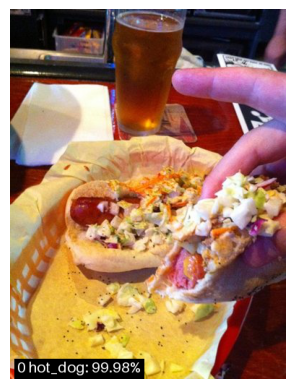

In [2]:
result, picture = model.classify_and_show("hot_dog_validation-20240303T060924Z-001/hot_dog_validation/268919.jpg",
                                          convert_to_bgr=False)

print("Class:", result["class_name"])
print("Confidence:", result["class_confidence"])
print("Очки по классам:", result["predictions"])

plt.imshow(picture)
plt.axis("off")
plt.show()

### Перебираем все картинки через os.listdir() и смотрим на результаты

In [3]:
correct = 0
total = 0
mistakes = []

for name in os.listdir():
    if "validation" not in name:
        continue

    folder = os.path.join(name, name.split("-")[0])
    true_index = 1 if name.startswith("not") else 0
    good = 0
    files = sorted(os.listdir(folder))

    for file_name in files:
        result = model.classify_image(os.path.join(folder, file_name))
        total += 1
        if result["class_index"] == true_index:
            good += 1
            correct += 1
        else:
            mistakes.append((file_name, result["class_name"], result["class_confidence"]))

    print(folder, "->", good, "из", len(files), "правильно")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

hot_dog_validation-20240303T060924Z-001\hot_dog_validation -> 242 из 250 правильно


not_hot_dog_validation-20240303T060915Z-001\not_hot_dog_validation -> 246 из 250 правильно

Вместе: 488 из 500 -> 97.6 %


In [4]:
print("Ошибки:")
for file_name, class_name, confidence in mistakes:
    print(" ", file_name, "->", class_name, round(confidence * 100, 1), "%")

Ошибки:
  207335.jpg -> 1 not_hot_dog 99.8 %
  259058.jpg -> 1 not_hot_dog 96.4 %
  285214.jpg -> 1 not_hot_dog 96.9 %
  505563.jpg -> 1 not_hot_dog 99.7 %
  570799.jpg -> 1 not_hot_dog 64.3 %
  583811.jpg -> 1 not_hot_dog 100.0 %
  602204.jpg -> 1 not_hot_dog 87.8 %
  651101.jpg -> 1 not_hot_dog 61.4 %
  47909.jpg -> 0 hot_dog 80.8 %
  56409.jpg -> 0 hot_dog 95.3 %
  66858.jpg -> 0 hot_dog 90.3 %
  80190.jpg -> 0 hot_dog 100.0 %


### Вывод по Заданию 1

Хот-доги: 242 из 250 = 96.8%. Не хот-доги: 246 из 250 = 98.4%. Вместе **488 из 500 = 97.6%**, 12 ошибок.
Из 12 ошибок 7 сделаны с уверенностью 95% и выше (одна даже 100%), остальные 5 - от 61% до 90%.
  То есть модель не «сомневается», а уверенно путает похожие блюда.
Причина - однотипные фото в обучении: в `hot_dog_train` в основном классический хот-дог в булке,
  а в проверке попались крупные планы где на фотографии много деталей и булка сливается с другой едой.

# Задание 2

Здесь обучили модель в Teachable Machine на трёх классах обуви: **кроссовки**, **ботинки**,
**туфли** (по 25+ фотографий на класс)

In [1]:
from IPython.display import Image, display

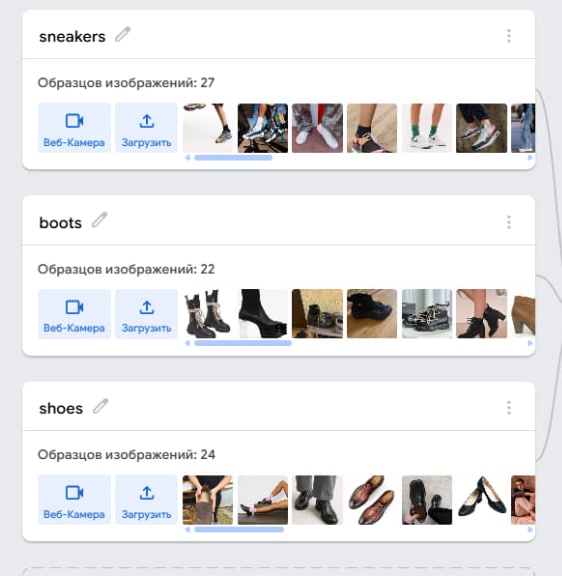

In [5]:
display(Image("C:/Users/almaz/Downloads/photo_2026-11-17_08-19-04.jpg", width=668))

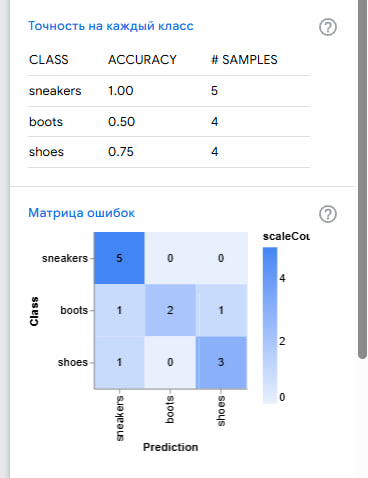

In [7]:
display(Image("C:/Users/almaz/Downloads/photo_2026-11-15_19-07-06.jpg", width=320))

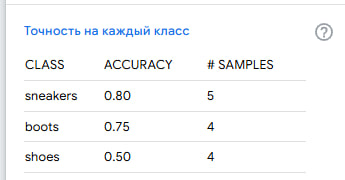

In [8]:
display(Image("C:/Users/almaz/Downloads/photo_2026-11-15_19-10-33.jpg", width=320))

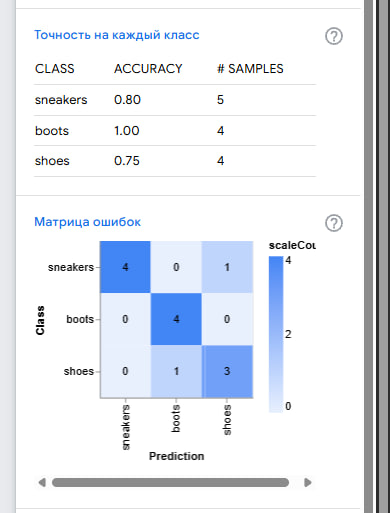

In [9]:
display(Image("C:/Users/almaz/Downloads/photo_2026-11-15_19-24-04.jpg", width=320))

In [5]:
model2 = TeachableMachine(
    model_path="keras_model.h5",
    labels_file_path="labels.txt",
)

labels = []
for line in open("labels.txt", "r", encoding="utf-8"):
    labels.append(line.strip().split(" ", 1))

for index, class_name in labels:
    print("Класс", index, "->", class_name, ":", len(os.listdir(class_name)), "файлов")

Teachable Machine Object is created successfully.
Класс 0 -> sneakers : 28 файлов
Класс 1 -> boots : 26 файлов
Класс 2 -> shoes : 26 файлов


### Перебираем все картинки из папок и считаем точность по каждому классу

In [6]:
correct = 0
total = 0
mistakes = []

for index, class_name in labels:
    files = sorted(os.listdir(class_name))
    good = 0

    for file_name in files:
        result = model2.classify_image(os.path.join(class_name, file_name))
        total += 1
        if result["class_index"] == int(index):
            good += 1
            correct += 1
        else:
            mistakes.append((class_name, file_name, result["class_name"], result["class_confidence"]))

    print(class_name, "->", good, "из", len(files), "правильно =", round(good / len(files) * 100, 1), "%")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

sneakers -> 26 из 28 правильно = 92.9 %


boots -> 26 из 26 правильно = 100.0 %


shoes -> 26 из 26 правильно = 100.0 %

Вместе: 78 из 80 -> 97.5 %


In [7]:
print("Ошибки:")
for class_name, file_name, predicted, confidence in mistakes:
    print(" ", class_name + "/" + file_name, "->", predicted, round(confidence * 100, 1), "%")

Ошибки:
  sneakers/images (20).jpg -> 2 shoes 97.0 %
  sneakers/images (7).jpg -> 2 shoes 68.6 %


### Проверка на новых фото

В папках `sneakers_test`, `boots_test`, `shoes_test` лежат снимки, которых модель при обучении не видела.
Это и есть честная проверка.

In [8]:
correct = 0
total = 0
mistakes = []

for index, class_name in labels:
    folder = class_name + "_test"
    files = sorted(os.listdir(folder))
    good = 0

    for file_name in files:
        result = model2.classify_image(os.path.join(folder, file_name))
        total += 1
        if result["class_index"] == int(index):
            good += 1
            correct += 1
        else:
            mistakes.append((folder, file_name, result["class_name"], result["class_confidence"]))

    print(folder, "->", good, "из", len(files), "правильно =", round(good / len(files) * 100, 1), "%")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

sneakers_test -> 6 из 7 правильно = 85.7 %


boots_test -> 7 из 8 правильно = 87.5 %


shoes_test -> 5 из 6 правильно = 83.3 %

Вместе: 18 из 21 -> 85.7 %


In [9]:
print("Ошибки:")
for folder, file_name, predicted, confidence in mistakes:
    print(" ", folder + "/" + file_name, "на самом деле", folder.split("_")[0], "->", predicted,
          round(confidence * 100, 1), "%")

Ошибки:
  sneakers_test/images (5).jpg на самом деле sneakers -> 1 boots 55.4 %
  boots_test/images (5).jpg на самом деле boots -> 0 sneakers 99.3 %
  shoes_test/k-1w-.jpg на самом деле shoes -> 1 boots 85.4 %


### Одна картинка глазами

Берём первую попавшуюся ошибку.

Файл:

 sneakers_test\images (5).jpg
Ответ модели: 1 boots -> 55.4 %
Очки по классам: [0.362, 0.554, 0.084]


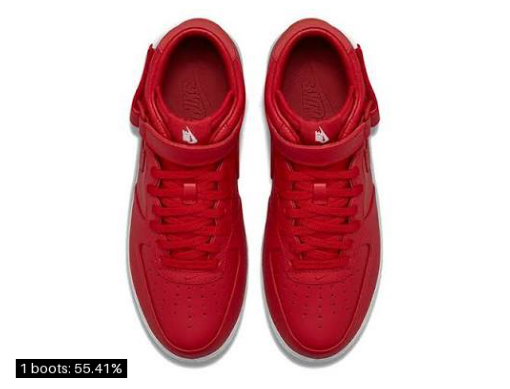

In [10]:
if mistakes:
    folder, file_name = mistakes[0][0], mistakes[0][1]
else:
    folder = labels[0][1] + "_test"
    file_name = sorted(os.listdir(folder))[0]

path = os.path.join(folder, file_name)
result, picture = model2.classify_and_show(path, convert_to_bgr=False)

print("Файл:", path)
print("Ответ модели:", result["class_name"], "->", round(result["class_confidence"] * 100, 1), "%")
print("Очки по классам:", [round(float(x), 3) for x in result["predictions"]])

plt.imshow(picture)
plt.axis("off")
plt.show()

### Вывод по Заданию 2

**1. Проверка на обучающих фото** - 78 из 80 = **97.5%**.
обучении, поэтому цифра завышена.

**2. Проверка на новых фото** - 18 из 21 = **85.7%**:
- кроссовки: 6 из 7 = 85.7%
- ботинки: 7 из 8 = 87.5%
- туфли: 5 из 6 = 83.3%

Вот это и есть настоящая точность модели. Она почти совпала с тем, что показал сам Teachable Machine
на своей тестовой выборке (11 из 13 = 84.6%).

**3. В чём модель путается.** Все три ошибки - только между соседними классами: кроссовки за ботинки,
ботинки за кроссовки, туфли за ботинки. Кроссовки с туфлями не перепутали ни разу.

# Задание 3

# Pocket AutoML: породы кошек на смартфоне

Приложение Pocket AutoML установлено из Google Play на эмулятор, там же всё и обучалось: модель считает на телефоне, и интернет для тренировки не нужен. Задача своя, классы  три породы кошек: мейкуны, сиамские, бенгальские.

### Вкладка "Данные"

Три класса, фотографии загружены из галереи прямо в приложении. Снимки разные: профиль,
лёжа, на улице и дома. Это нужно, чтобы модель училась узнавать по разным ракурсам.

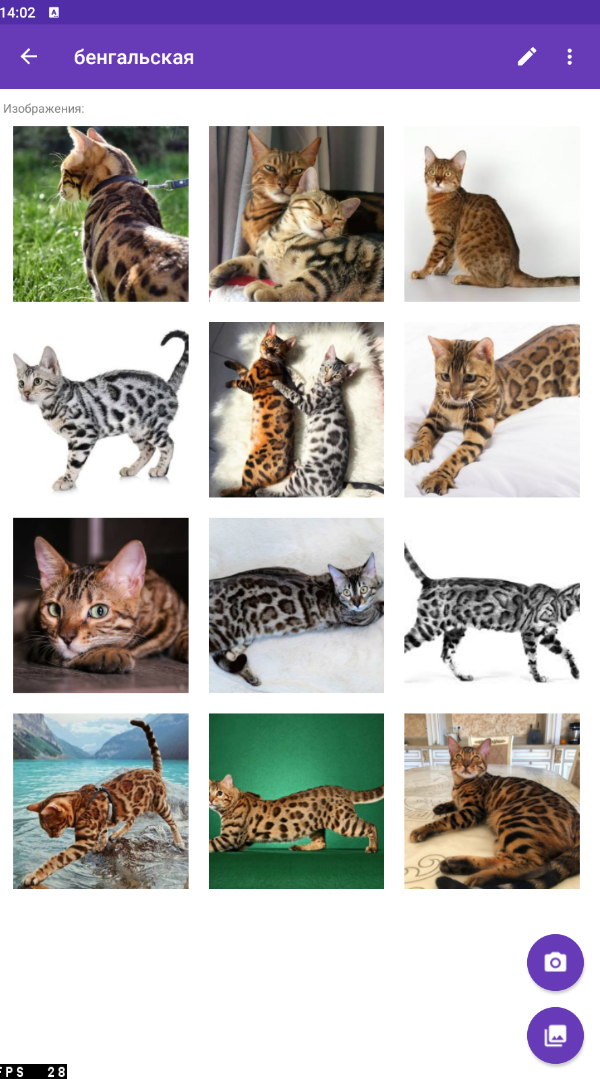

In [11]:
from IPython.display import Image, display
display(Image("AutoML/01_data_bengal.png", width=320))

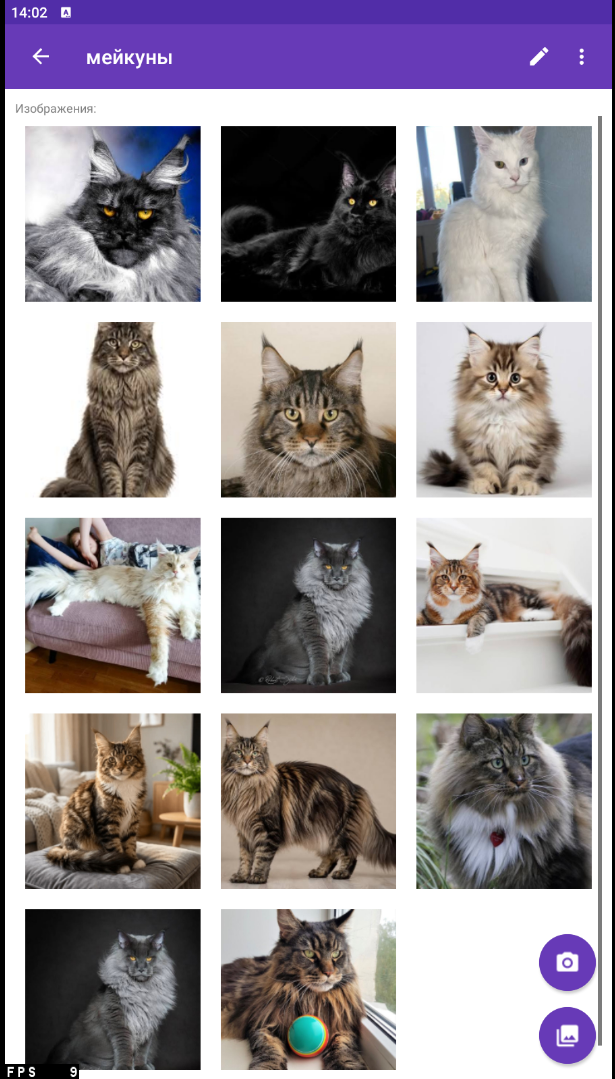

In [12]:
display(Image("AutoML/02_data_maine_coon.png", width=320))

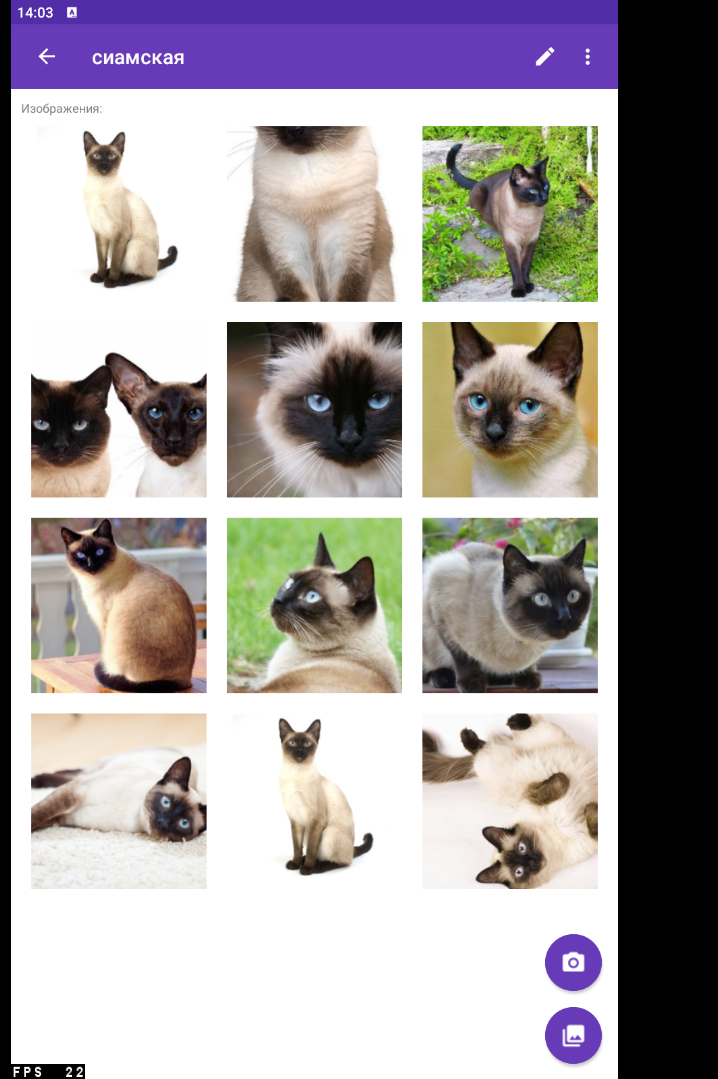

In [13]:
display(Image("AutoML/03_data_siam.png", width=320))

### Модель

Приложение само считает статистику: 37 тренировочных изображений, 12 распознаваний, из них
9 подтверждены. Точность указана диапазоном от 46,19% до 90,91% с 95% достоверностью - это не
одна цифра, а нижняя и верхняя граница, потому что примеров всего 12.

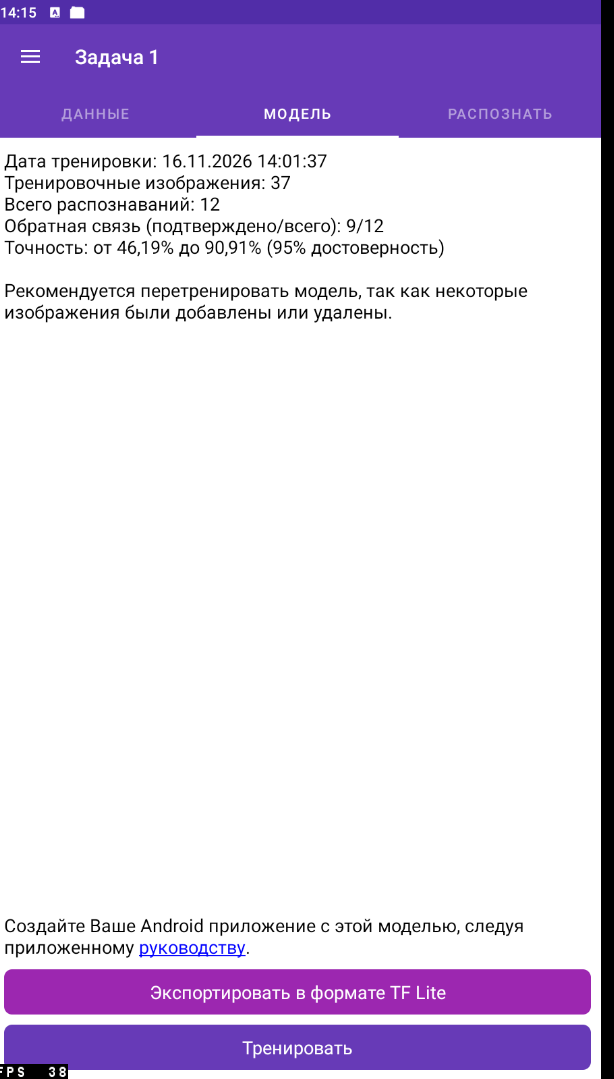

In [14]:
display(Image("AutoML/06_model_stats.png", width=320))

### Вкладка "Распознать", первый круг

Мейкун на диване определён верно - жмём "Подтвердить".

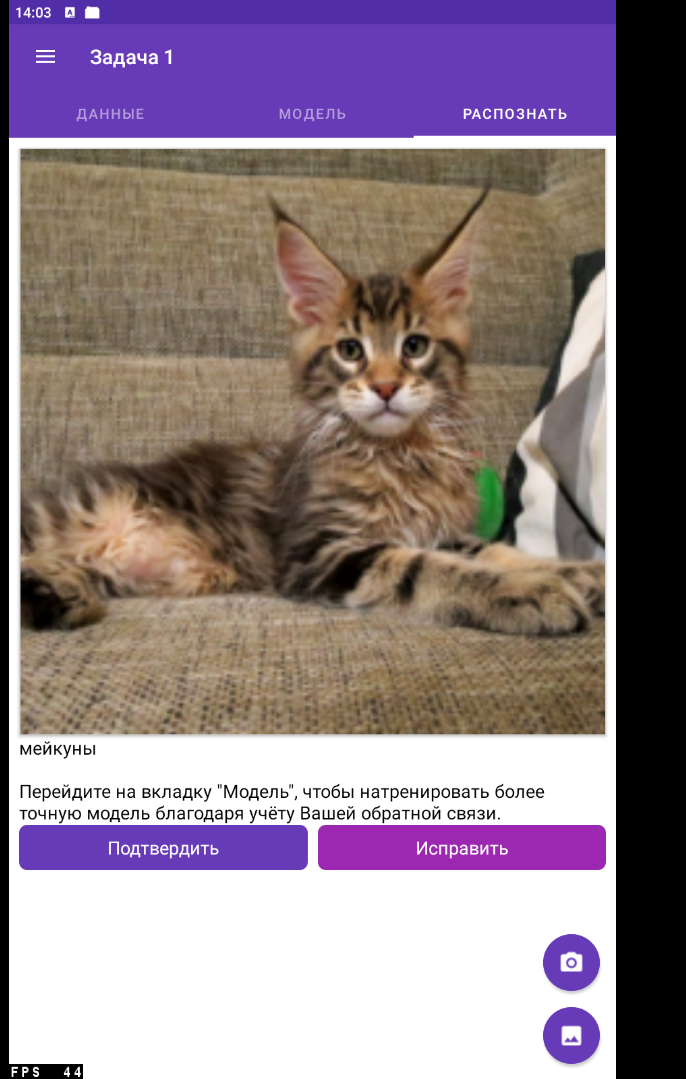

In [15]:
display(Image("AutoML/04_recognize_maine_coon_ok.png", width=320))

А это рыжий длинношёрстный кот. Модель выдала **бенгальская**, хотя это мейкун: сработал рыжий цвет
и полосатый рисунок, а не форма морды и размер.

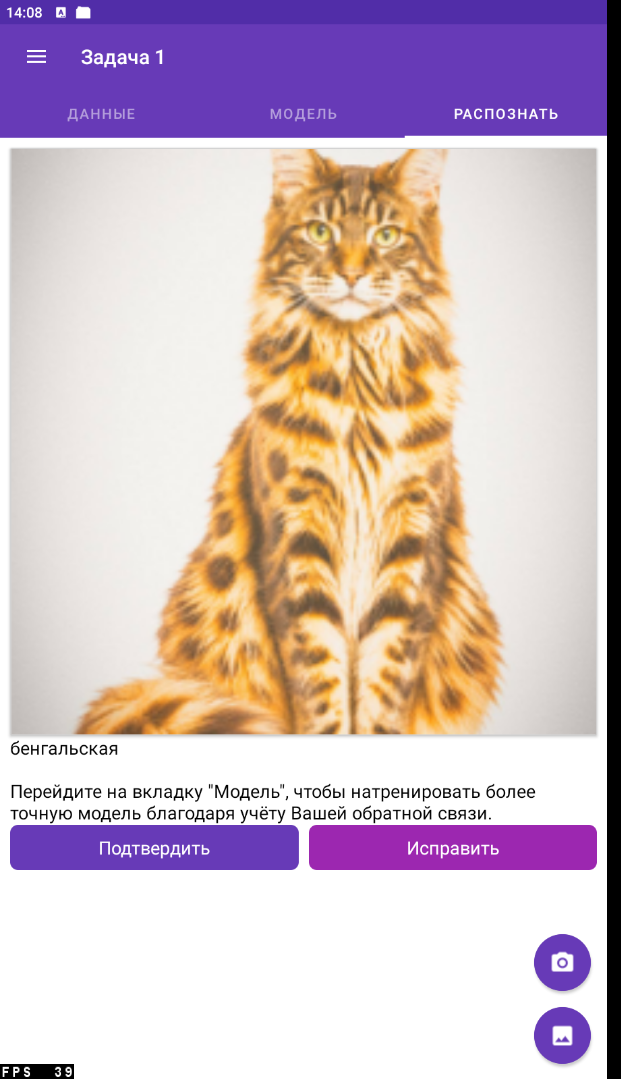

In [16]:
display(Image("AutoML/05_recognize_wrong_bengal.png", width=320))

### После обратной связи и повторной тренировки

Та же самая картинка, что выше. Модель переехала на новых данных и теперь отвечает **мейкуны**.

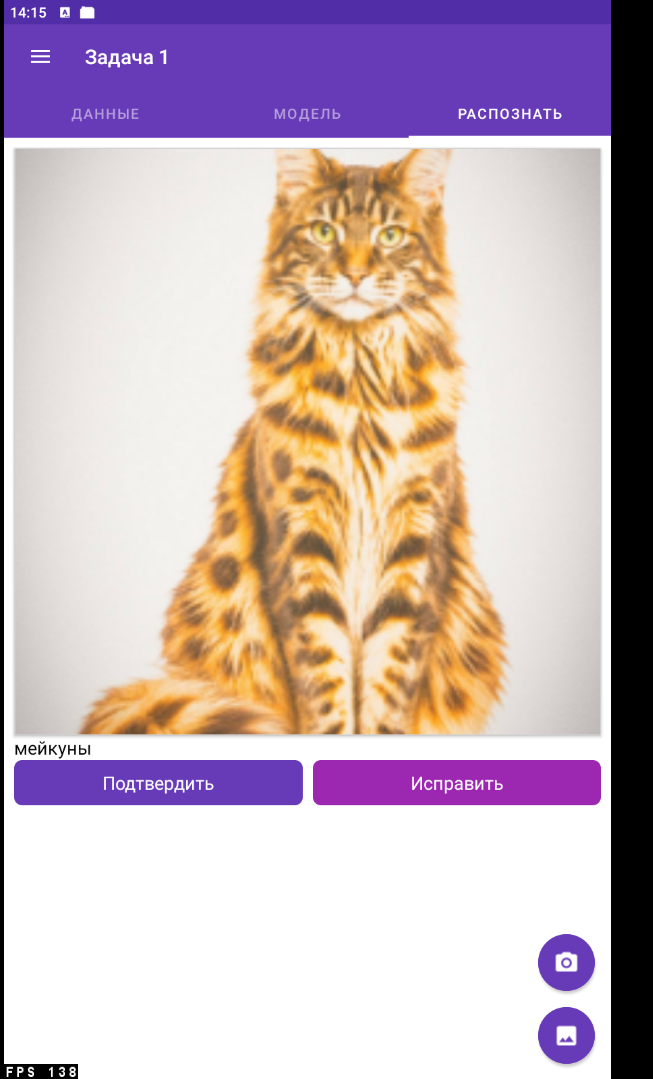

In [17]:
display(Image("AutoML/07_recognize_same_cat_after.png", width=320))

Чтоб быть убежденным, что модель научилась отличать мейкунов бенгальской окраски от бенгальской окраски, надо проверить еще одно изображение.

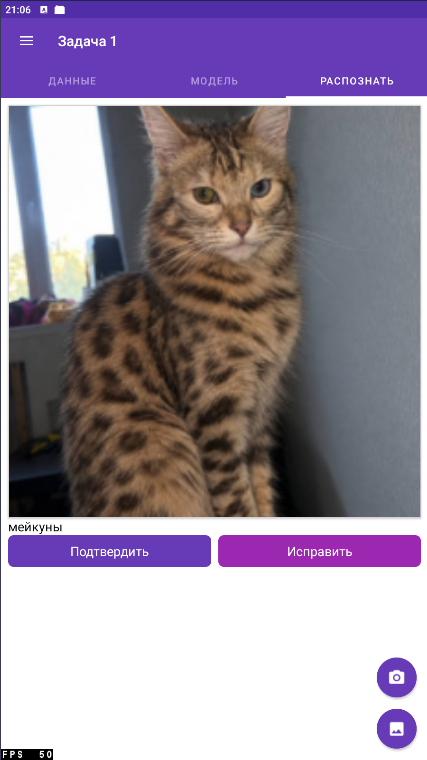

In [18]:
display(Image("AutoML/09_recognize_bengal_wrong.png", width=320))

Модель определила, можно сделать вывод, что она научилась.

### Вкладка "Модель" после второго круга

Сравниваем с тем, что было выше: тренировочных фото стало 37 -> 56, распознаваний 12 -> 25,
подтверждено 16 из 20. И главное - нижняя граница точности подтянулась с 46,19% до 58,09% при
той же верхней (90,91% -> 91,78%). То есть модель не столько начала угадывать чаще, сколько стала
реже промахиваться.

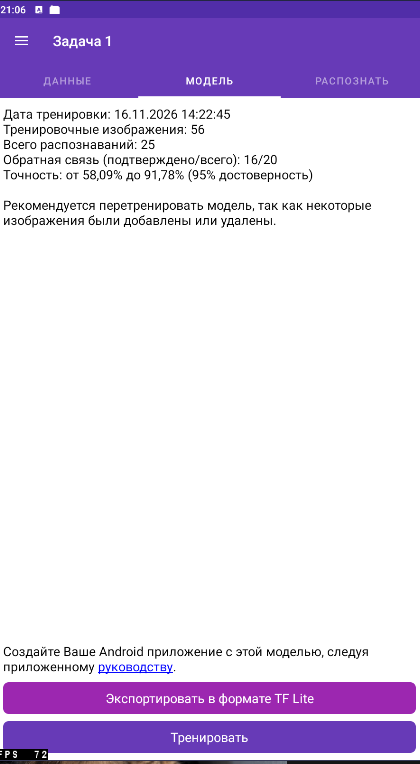

In [19]:
display(Image("AutoML/10_model_after_second_round.png", width=320))

### Вывод по Заданию 3

**Что получилось:** три класса (мейкуны, сиамские, бенгальские). Первый круг - 37 тренировочных фото,
12 распознаваний, 9 подтверждены, точность 46,19% - 90,91%. Второй круг после добавления фото и
повторной тренировки - 56 фото, 25 распознаваний, 16 из 20 подтверждены, точность 58,09% - 91,78%.

**Где ошибалась модель.** Ошибки были только между мейкунами и бенгалами, сиамских не путала ни разу.
Причина понятна: у сиамских признак один и очень яркий - тёмная морда и лапы на светлом теле, он
виден на любом фото. А мейкун и бенгал различаются размером, формой морды и длиной шерсти, и всё это
исчезает, если кот снят крупным планом или сбоку. Но при этом модель может путаться из-за пятен.

**Помогла обратная связь.** После того как рыжего кота исправили на мейкунов и потренировались
заново, та же картинка стала определяться правильно. Это видно на скриншотах выше: один и тот же
кадр до перетренировки - "бенгальская", после - "мейкуны" и в добавок сделанный новый кадр мейкуна тоже показал "мейкуны".

# Задание 4

# API к модели и приложение с графическим интерфейсом

Сервер встаёт на *http://127.0.0.1:5055*, Streamlit открывает *http://127.0.0.1:8501* в браузере.
Модель грузится один раз - на стороне API, окно ничего не считает, оно только отправляет картинку
и показывает то, что пришёл в ответе.

### GET-запрос: что отдаёт сервер

In [20]:
from api import app

client = app.test_client()

response = client.get("/")
print("Код:", response.status_code)
print(response.get_data(as_text=True))

Teachable Machine Object is created successfully.
Код: 200
{"classes":["sneakers","boots","shoes"],"get":"/predict?path=sneakers_test/images (5).jpg","model":"обувь","post":"/predict, картинка в поле file"}



In [21]:
response = client.get("/predict", query_string={"path": "shoes_test/k-1w-.jpg"})
data = response.get_json()

print("Код:", response.status_code)
print("Класс:", data["class"], "->", data["confidence_percent"], "%")
print("Индекс класса:", data["class_index"])
print("Очки по всем классам:")

for item in data["predictions"]:
    print("   ", item["class"], "-", item["probability"])

Код: 200
Класс: boots -> 85.4 %
Индекс класса: 1
Очки по всем классам:
    sneakers - 0.1376
    boots - 0.8538
    shoes - 0.0086


### POST-запрос: картинка телом запроса

In [22]:
picture = open("sneakers_test/images (5).jpg", "rb")

response = client.post("/predict", data={"file": picture}, content_type="multipart/form-data")
data = response.get_json()

print("Код:", response.status_code)
print("Класс:", data["class"], "->", data["confidence_percent"], "%")
print("Очки по всем классам:")

for item in data["predictions"]:
    print("   ", item["class"], "-", item["probability"])

Код: 200
Класс: boots -> 55.4 %
Очки по всем классам:
    sneakers - 0.3616
    boots - 0.5541
    shoes - 0.0843


### Ошибочные ответы

API не падает, а честно отвечает кодом и текстом ошибки - так приложение может показать пользователю
понятное сообщение.

In [23]:
response = client.get("/predict", query_string={"path": "net_takogo_faila.jpg"})
print("Код:", response.status_code, response.get_json())

response = client.post("/predict", data={})
print("Код:", response.status_code, response.get_json())

Код: 404 {'error': 'файл не найден', 'path': 'net_takogo_faila.jpg'}
Код: 400 {'error': 'нет файла в поле file'}


# Изображения приложения

Так выглядит окно `app.py` по шагам. Модель в этот момент живёт в `api.py`, окно только отправляет
картинку и показывает то, что вернулось в ответе.

### Шаг 1. Первоначальное окно

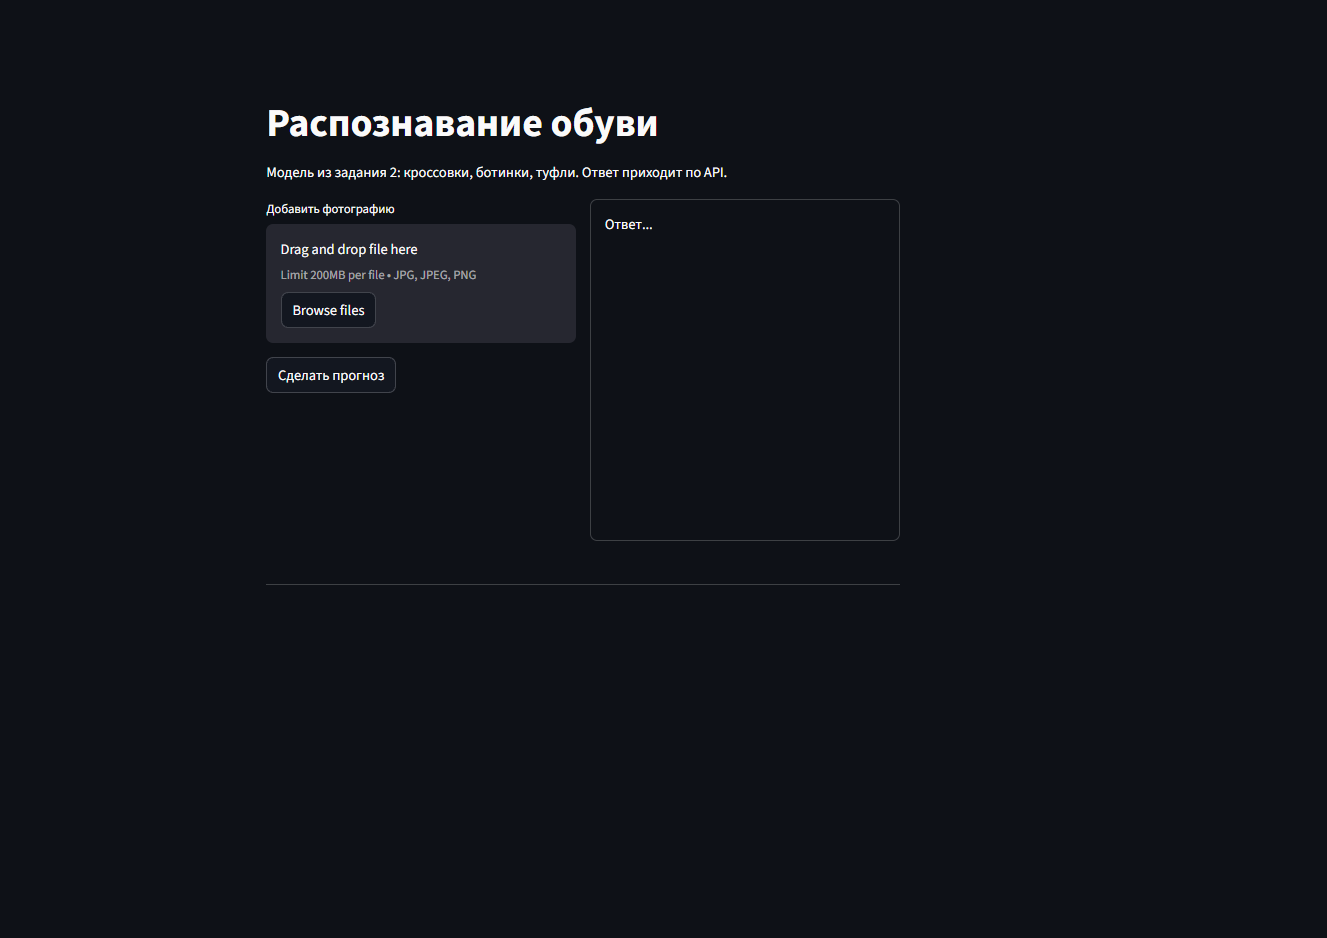

In [24]:
display(Image("app_shots/app_01_start.png", width=700))

### Шаг 2. Добавили фото

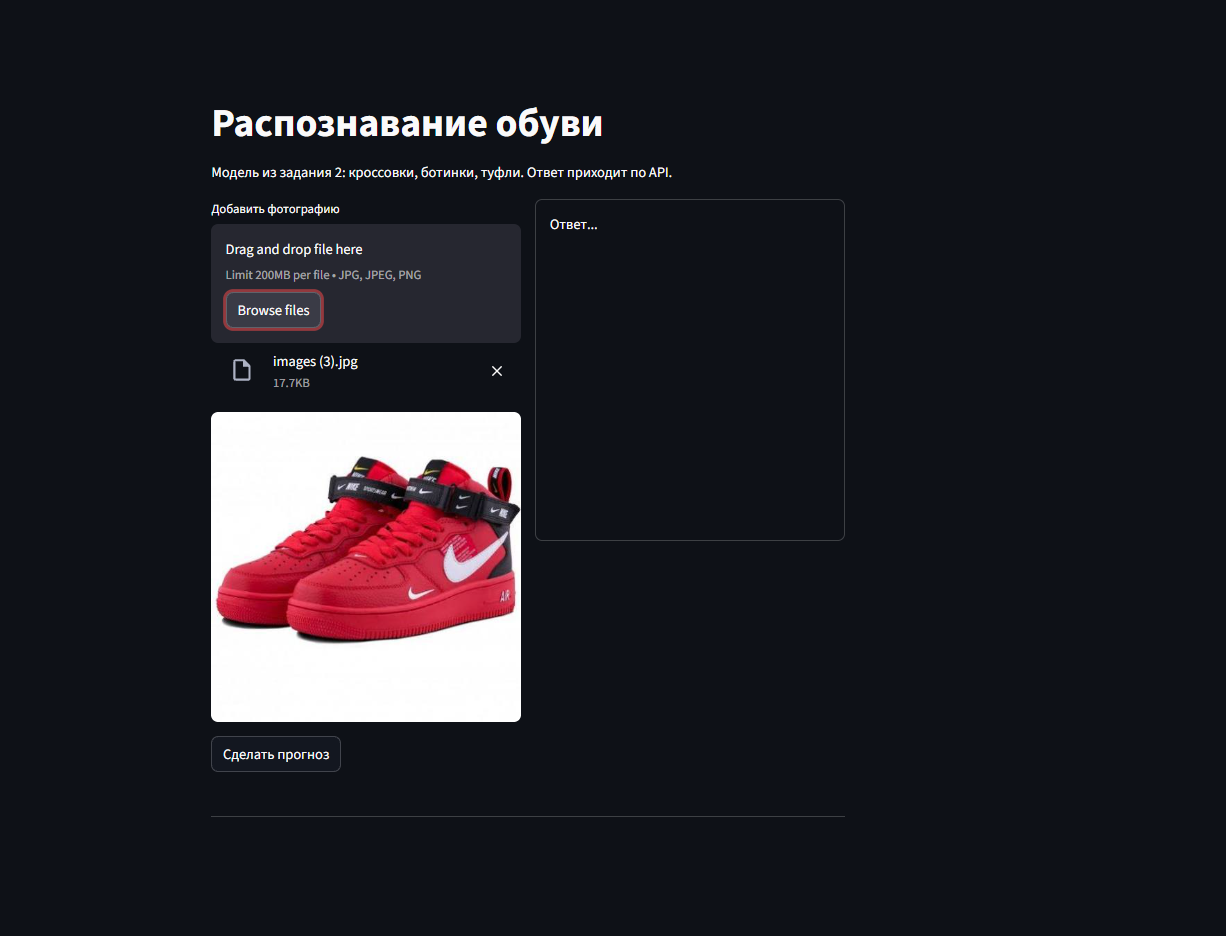

In [25]:
display(Image("app_shots/app_02_photo_loaded.png", width=700))

### Шаг 3. Ответ пришёл

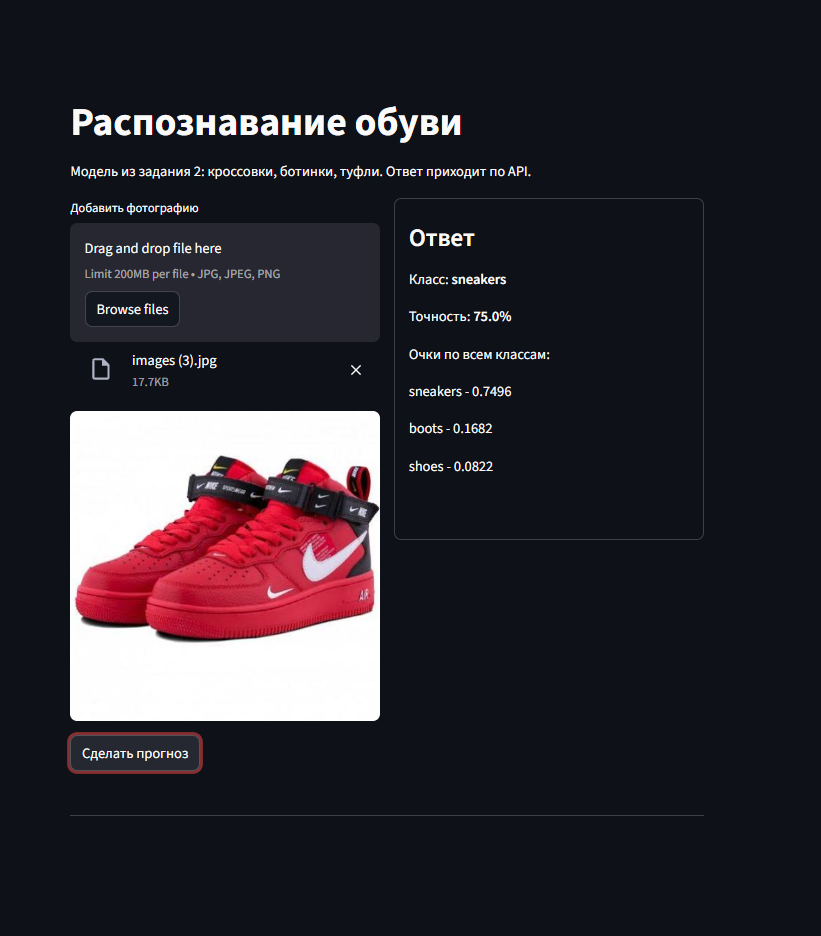

In [26]:
display(Image("app_shots/app_03_answer.png", width=460))

### Вывод по Заданию 4

Программный интерфейс готов: api.py отдаёт результат распознавания и точность в виде JSON по двум
способам - GET (путь до файла) и POST (сама картинка). Приложение app.py загружает изображение,
ходит в этот API и показывает класс, точность и очки по всем трём классам.